# 07 - Validation on the Hold-out Set

**Goal:** judge the scorecard on data it has never seen. This is the **first time the hold-out set is opened**. Nothing is refitted here: bins (`binning_spec.json`),
coefficients (`model_spec.json`) and scaling (`scorecard_spec.json`) are loaded frozen from notebooks 04-06. Grade cut points are also defined on the **development** score.

**What a validator checks**
1. **Discrimination** - does the score rank bad customers below good ones? (AUC, Gini, KS, with a confidence interval)
2. **Rank ordering** - does the bad rate rise steadily from the best grade to the worst?
3. **Calibration** - does the predicted PD match the observed bad rate? (This is a different question from discrimination.)
4. **Stability** - does the hold-out population look like the development population? (PSI / CSI)
5. **Cut-off** - what approval rate and bad rate do we get at each score threshold?

**Conventions:** higher score = safer. For metrics that expect "risk", we pass `-score` (or the PD).

In [1]:
import sys, json
sys.path.insert(0, "../src")

from pathlib import Path
for _p in ("../data/processed", "../outputs/figures", "../outputs/metrics", "../outputs/scorecard"):
    Path(_p).mkdir(parents=True, exist_ok=True)   # Git does not keep empty folders

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.metrics import roc_curve

from feature_engineering import WoEBinner
from scorecard import Scorecard, score_to_pd
from evaluation import (discrimination_metrics, bootstrap_ci, grade_edges, assign_grade, rank_ordering_table,
                        calibration_table, hosmer_lemeshow, probability_scores, psi, cutoff_table)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

dev = pd.read_csv("../data/processed/dev.csv", index_col="id")
hold = pd.read_csv("../data/processed/holdout.csv", index_col="id")

binners = {v: WoEBinner.from_dict(s) for v, s in json.load(open("../outputs/scorecard/binning_spec.json")).items()}
model = json.load(open("../outputs/scorecard/model_spec.json"))
spec = json.load(open("../outputs/scorecard/scorecard_spec.json"))
factor, offset = spec["factor"], spec["offset"]
card = Scorecard(binners, model["intercept"], model["coefficients"], factor, offset, round_points=True)

s_dev, s_hold = card.score(dev), card.score(hold)
pd_dev, pd_hold = score_to_pd(s_dev, factor, offset), score_to_pd(s_hold, factor, offset)
y_dev, y_hold = dev["target"], hold["target"]
print(f"Development: {len(dev):,} rows, {y_dev.sum():,} bad | Hold-out: {len(hold):,} rows, {y_hold.sum():,} bad")
print("Score range  dev:", s_dev.min(), "-", s_dev.max(), "| hold-out:", s_hold.min(), "-", s_hold.max())

Development: 104,987 rows, 7,020 bad | Hold-out: 45,012 rows, 3,006 bad
Score range  dev: 390.0 - 632.0 | hold-out: 402.0 - 632.0


## 1. Discrimination: AUC, Gini, KS

In [2]:
m_dev = discrimination_metrics(y_dev, -s_dev)
m_hold = discrimination_metrics(y_hold, -s_hold)
ci = bootstrap_ci(y_hold, -s_hold.to_numpy(), n_boot=500, seed=42)
disc = pd.DataFrame({"development": m_dev, "hold-out": m_hold}).T
disc["auc_95ci"] = ["", f"[{ci['auc_lo']:.4f}, {ci['auc_hi']:.4f}]"]
disc["gini_95ci"] = ["", f"[{ci['gini_lo']:.4f}, {ci['gini_hi']:.4f}]"]
disc

,auc,gini,ks,auc_95ci,gini_95ci
development,0.858468,0.716937,0.553668,,
hold-out,0.859608,0.719215,0.564962,"[0.8523, 0.8666]","[0.7046, 0.7332]"


**Reading:** hold-out AUC (~0.860) is as high as on development (~0.858); the difference is well inside the bootstrap confidence interval. So there is **no overfitting**.
The value is in the normal range for this dataset (0.85-0.86) and far from 0.95, so there is no sign of leakage either.
Gini = 2 x AUC - 1 carries the same information on a different scale. The Gini of ~0.72 and KS of ~0.56 are strong for a consumer application scorecard, but benchmarks depend on product and data,
so read them as a sanity check, not as a pass mark.

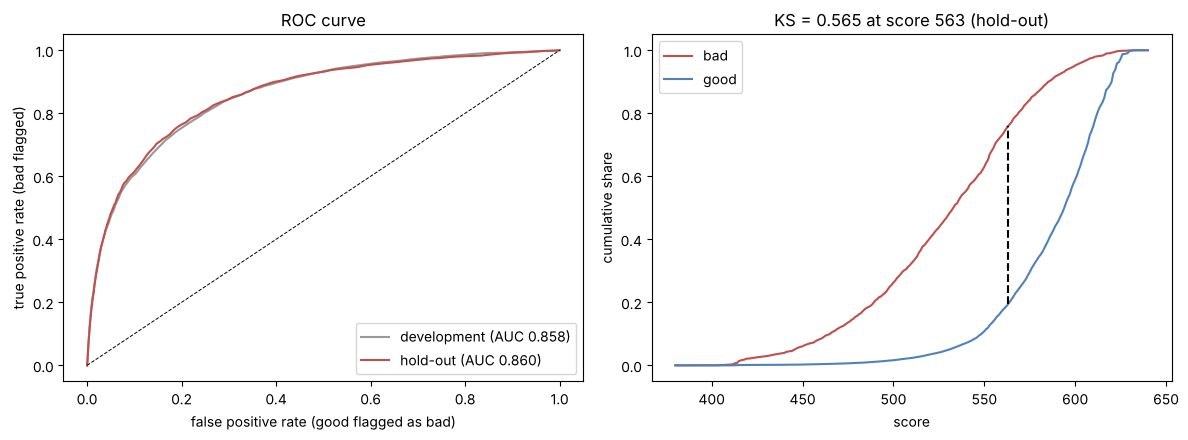

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for name, y_, s_, c in [("development", y_dev, s_dev, "#999999"), ("hold-out", y_hold, s_hold, "#c0504d")]:
    fpr, tpr, _ = roc_curve(y_, -s_)
    ax[0].plot(fpr, tpr, color=c, label=f"{name} (AUC {discrimination_metrics(y_, -s_)['auc']:.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.7); ax[0].set_xlabel("false positive rate (good flagged as bad)")
ax[0].set_ylabel("true positive rate (bad flagged)"); ax[0].legend(); ax[0].set_title("ROC curve")

grid = np.arange(380, 641, 1)
cum_bad = [(s_hold[y_hold == 1] <= g).mean() for g in grid]
cum_good = [(s_hold[y_hold == 0] <= g).mean() for g in grid]
k = int(np.argmax(np.array(cum_bad) - np.array(cum_good)))
ax[1].plot(grid, cum_bad, color="#c0504d", label="bad"); ax[1].plot(grid, cum_good, color="#4f81bd", label="good")
ax[1].vlines(grid[k], cum_good[k], cum_bad[k], color="k", ls="--")
ax[1].set_title(f"KS = {cum_bad[k] - cum_good[k]:.3f} at score {grid[k]} (hold-out)")
ax[1].set_xlabel("score"); ax[1].set_ylabel("cumulative share"); ax[1].legend()
plt.tight_layout(); plt.savefig("../outputs/figures/roc_and_ks_holdout.png", dpi=130); plt.show()
assert np.isclose(cum_bad[k] - cum_good[k], m_hold["ks"], atol=2e-3)

The KS gap computed by hand from the two cumulative curves matches the library value, which is a quick check on the metric.

## 2. Rank ordering by grade

Customers are split into 10 grades using **score quantiles of the development set** (so the cut points are fixed before looking at the hold-out). Grade 1 is the safest, grade 10 the riskiest.
A healthy scorecard shows a bad rate that rises steadily from grade 1 to grade 10, **on both sets**.

In [4]:
edges = grade_edges(s_dev, 10)
print("Grade cut points (score):", edges)
ro_dev = rank_ordering_table(y_dev, s_dev, pd_dev, edges)
ro_hold = rank_ordering_table(y_hold, s_hold, pd_hold, edges)
for name, t in [("development", ro_dev), ("hold-out", ro_hold)]:
    print(f"\n{name}")
    display(t.round(4))
    assert np.all(np.diff(t["bad_rate"]) > 0), f"rank ordering broken on {name}"
print("\nOK: bad rate strictly increases from grade 1 to grade 10 on both sets")

Grade cut points (score): [540. 559. 572. 583. 592. 600. 606. 612. 620.]

development


,grade,rows,bad,bad_rate,avg_pd,min_score,max_score,pct_rows
0,1,11076,53,0.0048,0.0088,620.0,632.0,0.1055
1,2,11164,65,0.0058,0.0117,612.0,619.0,0.1063
2,3,10577,109,0.0103,0.0147,606.0,611.0,0.1007
3,4,9456,113,0.0120,0.0180,600.0,605.0,0.0901
4,5,11489,232,0.0202,0.0228,592.0,599.0,0.1094
5,6,10265,286,0.0279,0.0307,583.0,591.0,0.0978
6,7,10219,493,0.0482,0.0428,572.0,582.0,0.0973
7,8,10173,726,0.0714,0.0631,559.0,571.0,0.0969
8,9,10233,1206,0.1179,0.1005,540.0,558.0,0.0975
9,10,10335,3737,0.3616,0.3511,390.0,539.0,0.0984



hold-out


,grade,rows,bad,bad_rate,avg_pd,min_score,max_score,pct_rows
0,1,4735,28,0.0059,0.0088,620.0,632.0,0.1052
1,2,4556,33,0.0072,0.0117,612.0,619.0,0.1012
2,3,4639,44,0.0095,0.0147,606.0,611.0,0.1031
3,4,4000,52,0.0130,0.0179,600.0,605.0,0.0889
4,5,4940,77,0.0156,0.0228,592.0,599.0,0.1097
5,6,4351,122,0.0280,0.0306,583.0,591.0,0.0967
6,7,4489,198,0.0441,0.0429,572.0,582.0,0.0997
7,8,4407,292,0.0663,0.0631,559.0,571.0,0.0979
8,9,4361,514,0.1179,0.1007,540.0,558.0,0.0969
9,10,4534,1646,0.3630,0.3526,402.0,539.0,0.1007



OK: bad rate strictly increases from grade 1 to grade 10 on both sets


**Reading:** the bad rate climbs from about 0.5% in grade 1 to about 36% in grade 10 on both sets, with no inversion. The riskiest grade is roughly **60-75x** riskier than the safest (61x on hold-out, 75x on development).
Grade 10 is wide (scores 402-539) because the distribution has a long left tail of very risky customers; it alone contains more than half of all bad cases.

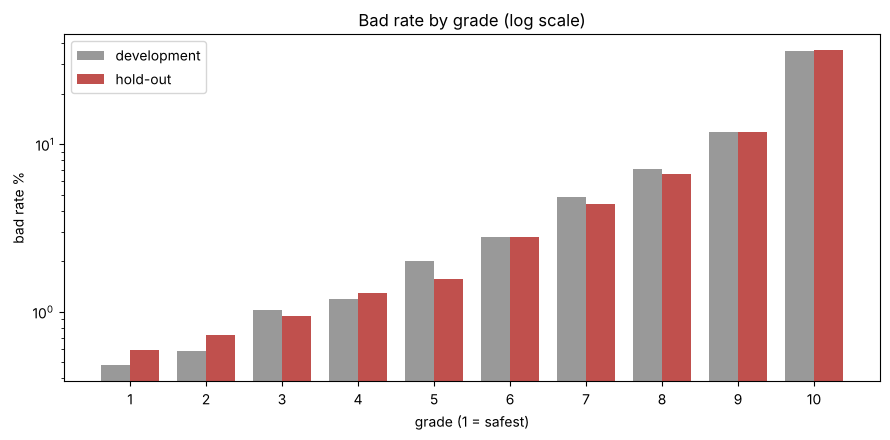

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
w = 0.38; x = np.arange(1, 11)
ax.bar(x - w / 2, ro_dev["bad_rate"] * 100, w, label="development", color="#999999")
ax.bar(x + w / 2, ro_hold["bad_rate"] * 100, w, label="hold-out", color="#c0504d")
ax.set_xticks(x); ax.set_xlabel("grade (1 = safest)"); ax.set_ylabel("bad rate %"); ax.set_yscale("log")
ax.set_title("Bad rate by grade (log scale)"); ax.legend()
plt.tight_layout(); plt.savefig("../outputs/figures/rank_ordering_by_grade.png", dpi=130); plt.show()

## 3. Calibration: is the PD itself right?

Discrimination only needs the **order** to be right. Calibration asks whether the **level** is right: a customer scored at PD = 2% should default about 2% of the time.
A model can rank perfectly and still be useless for provisioning or pricing if the levels are off.

In [6]:
print("Overall calibration")
overall = pd.DataFrame({"development": probability_scores(y_dev, pd_dev), "hold-out": probability_scores(y_hold, pd_hold)}).T
display(overall.round(5))

lg = lambda p: np.log(p / (1 - p))
rows = {}
for name, y_, p_ in [("development", y_dev, pd_dev), ("hold-out", y_hold, pd_hold)]:
    m = sm.Logit(y_, sm.add_constant(lg(p_))).fit(disp=0)
    rows[name] = {"intercept": m.params.iloc[0], "slope": m.params.iloc[1], "slope_se": m.bse.iloc[1]}
display(pd.DataFrame(rows).T.round(3))

Overall calibration


,brier,log_loss,mean_pd,observed_bad_rate
development,0.05018,0.18282,0.06541,0.06687
hold-out,0.05024,0.18269,0.06641,0.06678


,intercept,slope,slope_se
development,0.018,0.994,0.010
hold-out,-0.025,0.984,0.015


**Reading:** the average predicted PD (6.6%) matches the observed bad rate (6.7%), and the calibration regression has an intercept near 0 and a slope near 1 (0.98).
So **overall** the PD is well calibrated, with no resampling or class weights needed.

*Which PD is this?* Throughout this notebook the PD is the one **implied by the rounded scorecard score**, because that is what would be used in practice.
Rounding raises scores by about 1 point on average (notebook 06), so on development the mean PD is 6.54% instead of exactly the bad rate (6.69%) as for the
unrounded model in notebook 05. The difference is small and does not change any conclusion below.

In [7]:
grades_hold = assign_grade(s_hold, edges)
grades_dev = assign_grade(s_dev, edges)
cal_hold = calibration_table(y_hold, pd_hold, grades_hold)
cal_dev = calibration_table(y_dev, pd_dev, grades_dev)
hl = hosmer_lemeshow(y_hold, pd_hold, grades_hold, dof_reduction=0)   # independent sample: groups and PDs fixed on development, so df = 10
print("Hold-out calibration by grade"); display(cal_hold.round(4))
print("Development calibration by grade (same pattern would mean a structural issue, not hold-out noise)")
display(cal_dev[["grade", "avg_pd", "bad_rate", "ratio_obs_pred"]].round(4))
print("Hosmer-Lemeshow (hold-out):", {k: round(v, 6) for k, v in hl.items()})

Hold-out calibration by grade


,grade,rows,bad,avg_pd,bad_rate,ratio_obs_pred,binom_p_value
0,1,4735,28,0.0088,0.0059,0.6696,0.0294
1,2,4556,33,0.0117,0.0072,0.6184,0.0037
2,3,4639,44,0.0147,0.0095,0.6453,0.0022
3,4,4000,52,0.0179,0.0130,0.7244,0.0170
4,5,4940,77,0.0228,0.0156,0.6844,0.0004
5,6,4351,122,0.0306,0.0280,0.9151,0.3334
6,7,4489,198,0.0429,0.0441,1.0281,0.6853
7,8,4407,292,0.0631,0.0663,1.0508,0.3855
8,9,4361,514,0.1007,0.1179,1.1709,0.0002
9,10,4534,1646,0.3526,0.3630,1.0295,0.1440


Development calibration by grade (same pattern would mean a structural issue, not hold-out noise)


,grade,avg_pd,bad_rate,ratio_obs_pred
0,1,0.0088,0.0048,0.5427
1,2,0.0117,0.0058,0.4978
2,3,0.0147,0.0103,0.6997
3,4,0.0180,0.0120,0.6657
4,5,0.0228,0.0202,0.8857
5,6,0.0307,0.0279,0.9083
6,7,0.0428,0.0482,1.1267
7,8,0.0631,0.0714,1.1315
8,9,0.1005,0.1179,1.1724
9,10,0.3511,0.3616,1.0299


Hosmer-Lemeshow (hold-out): {'hl_statistic': 56.520416, 'df': 10, 'p_value': 0.0}


**Reading - an honest finding.** Inside the grades, calibration is **not perfect**:
- In the safest five grades (1-5) the model **over-predicts** the PD: observed/predicted is about 0.6-0.7 (for example grade 1: predicted 0.9%, observed 0.6%).
- Grade 9 is slightly **under-predicted** (ratio 1.17).
- The Hosmer-Lemeshow test (10 groups; 10 degrees of freedom because nothing was fitted on the hold-out) rejects (p far below 0.001). With 45,000 rows this test is very sensitive and flags even modest deviations, but the pattern is consistent, so we do not dismiss it.

The **development** table shows the same shape (grade 1: predicted 0.9%, observed 0.5%), so this is a **structural limitation of the model form** (a logistic regression on a few coarse WoE bins cannot bend enough in the low-risk tail), not noise in the hold-out sample.
The direction is conservative (it overstates risk for good customers), which matters less for a decline decision but does matter for pricing and provisioning.

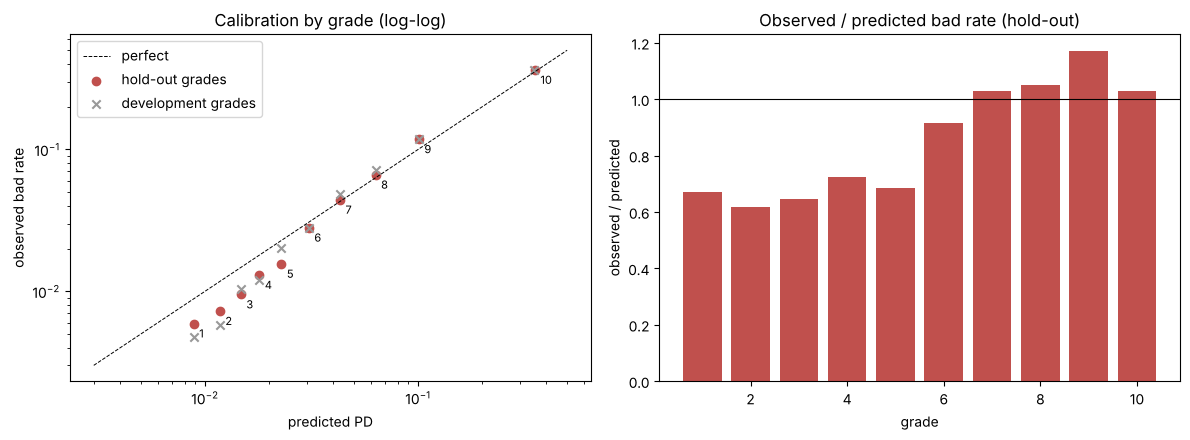

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot([0.003, 0.5], [0.003, 0.5], "k--", lw=0.7, label="perfect")
ax[0].scatter(cal_hold["avg_pd"], cal_hold["bad_rate"], color="#c0504d", label="hold-out grades")
ax[0].scatter(cal_dev["avg_pd"], cal_dev["bad_rate"], color="#999999", marker="x", label="development grades")
for r in cal_hold.itertuples():
    ax[0].annotate(str(r.grade), (r.avg_pd, r.bad_rate), textcoords="offset points", xytext=(4, -10), fontsize=8)
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].set_xlabel("predicted PD"); ax[0].set_ylabel("observed bad rate")
ax[0].set_title("Calibration by grade (log-log)"); ax[0].legend()
ax[1].bar(cal_hold["grade"], cal_hold["ratio_obs_pred"], color="#c0504d")
ax[1].axhline(1, color="k", lw=0.8); ax[1].set_xlabel("grade"); ax[1].set_ylabel("observed / predicted"); ax[1].set_title("Observed / predicted bad rate (hold-out)")
plt.tight_layout(); plt.savefig("../outputs/figures/calibration_by_grade.png", dpi=130); plt.show()

### Can we fix it? Two recalibration options, both learned on the development set only

1. **Linear recalibration** (a logistic regression of the outcome on the logit of the PD).
2. **Grade-level PD ("master scale")**: every customer in a grade gets the development bad rate of that grade as PD. This is how banks usually report PD for provisioning and pricing.

In [9]:
# Option 1: linear recalibration fitted on development
rec = sm.Logit(y_dev, sm.add_constant(lg(pd_dev))).fit(disp=0)
pd_hold_lin = rec.predict(sm.add_constant(lg(pd_hold)))

# Option 2: master scale (development bad rate per grade)
master = y_dev.groupby(grades_dev).mean().rename("pd_master")
pd_hold_master = grades_hold.map(master)

cmp = pd.DataFrame({
    "original PD": {**probability_scores(y_hold, pd_hold), "hl_p_value": hl["p_value"]},
    "linear recalibration": {**probability_scores(y_hold, pd_hold_lin), "hl_p_value": hosmer_lemeshow(y_hold, pd_hold_lin, grades_hold, dof_reduction=0)["p_value"]},
    "grade master scale": {**probability_scores(y_hold, pd_hold_master), "hl_p_value": hosmer_lemeshow(y_hold, pd_hold_master, grades_hold, dof_reduction=0)["p_value"]},
}).T
display(cmp.round(5))
display(calibration_table(y_hold, pd_hold_master, grades_hold)[["grade", "avg_pd", "bad_rate", "ratio_obs_pred", "binom_p_value"]].round(4))

,brier,log_loss,mean_pd,observed_bad_rate,hl_p_value
original PD,0.05024,0.18269,0.06641,0.06678,0.00000
linear recalibration,0.05021,0.18270,0.06788,0.06678,0.00000
grade master scale,0.05141,0.18419,0.06777,0.06678,0.26644


,grade,avg_pd,bad_rate,ratio_obs_pred,binom_p_value
0,1,0.0048,0.0059,1.2358,0.2462
1,2,0.0058,0.0072,1.2440,0.2046
2,3,0.0103,0.0095,0.9204,0.6623
3,4,0.0120,0.0130,1.0879,0.5125
4,5,0.0202,0.0156,0.7719,0.0199
5,6,0.0279,0.0280,1.0064,0.9266
6,7,0.0482,0.0441,0.9143,0.2098
7,8,0.0714,0.0663,0.9284,0.1979
8,9,0.1179,0.1179,1.0001,1.0000
9,10,0.3616,0.3630,1.0040,0.8408


**Reading:**
- **Linear recalibration does not help** (HL p-value still far below 0.001): the problem is the *shape*, not a global shift, which is exactly what the slope near 1 told us.
- **The grade master scale fixes the grade-level calibration** (HL p-value ~0.27, ratios mostly close to 1; only grade 5 at 0.77 remains individually significant), at a small cost in Brier score because all customers within a grade share one PD.
- Practical conclusion: use the **score for ranking and decisions**, and report **PD per grade from the master scale** for provisioning and pricing. This is a legitimate finding for the validation report, not something to hide.

*Caveat:* even after this, the safest grades have only 28-77 bad cases each in the hold-out, so their observed rates are inherently noisy.

## 4. Stability: PSI and CSI

**PSI** compares the score distribution of two populations; **CSI** does the same for each input variable. With a random split we expect almost no shift. The same functions will be used in monitoring,
where the comparison is between development and a later period. Rule of thumb: < 0.1 stable, 0.1-0.25 watch, > 0.25 major shift.

In [10]:
score_psi = psi(s_dev, s_hold, edges)
print(f"Score PSI (development vs hold-out) = {score_psi:.5f}")

def csi(var):
    b = binners[var]
    k = len(b.woe_) + (1 if b.missing_mode_ == "own_bin" else 0)
    e = np.bincount(b.bin_index(dev[var]).to_numpy(), minlength=k) / len(dev)
    a = np.bincount(b.bin_index(hold[var]).to_numpy(), minlength=k) / len(hold)
    e, a = np.clip(e, 1e-6, None), np.clip(a, 1e-6, None)
    return float(((a - e) * np.log(a / e)).sum())

csi_tbl = pd.DataFrame({"variable": list(model["coefficients"]), "csi": [csi(v) for v in model["coefficients"]]})
csi_tbl["reading"] = np.where(csi_tbl["csi"] < 0.1, "stable", "check")
csi_tbl.sort_values("csi", ascending=False).reset_index(drop=True).round(5)

Score PSI (development vs hold-out) = 0.00046


,variable,csi,reading
0,age,0.00033,stable
1,n_30_59_late,0.00026,stable
2,n_open_lines,0.00022,stable
3,n_60_89_late,0.00021,stable
4,n_90_late,0.00020,stable
5,revolving_util,0.00019,stable
6,debt_ratio,0.00015,stable
7,n_dependents,0.00014,stable
8,n_real_estate,0.00009,stable


**Reading:** score PSI is about 0.0005 and every CSI is tiny, as expected for a random split of one population. This only shows that the split is clean;
it says nothing about stability **over time**, which this dataset cannot test (no dates). That is why monitoring and out-of-time validation are on the Phase 2 list.

## 5. Cut-off table

Approve a customer if score >= cut-off. For each cut-off: share approved, bad rate among approved and rejected, and what share of all bad (good) customers would be rejected.

In [11]:
cutoffs = [500, 520, 540, 550, 560, 570, 580, 590, 600]
cut = cutoff_table(y_hold, s_hold, cutoffs)
cut

,cutoff,approval_rate,bad_rate_approved,bad_rate_rejected,bads_rejected_share,goods_rejected_share
0,500.0,0.968275,0.051372,0.537115,0.255156,0.015736
1,520.0,0.942526,0.042805,0.459992,0.395875,0.033257
2,540.0,0.899271,0.033598,0.363035,0.547572,0.068752
3,550.0,0.862326,0.029396,0.300952,0.620426,0.103128
4,560.0,0.794966,0.023084,0.236212,0.725216,0.167809
5,570.0,0.719897,0.018269,0.191466,0.803061,0.242680
6,580.0,0.629343,0.014226,0.156018,0.865935,0.335214
7,590.0,0.526371,0.010594,0.129227,0.916500,0.441937
8,600.0,0.398338,0.008756,0.105199,0.947771,0.576894


{'approval_rate': np.float64(0.795), 'bad_rate_approved': np.float64(0.0231), 'bads_rejected_share': np.float64(0.7252)}
OK: table row matches the manual calculation


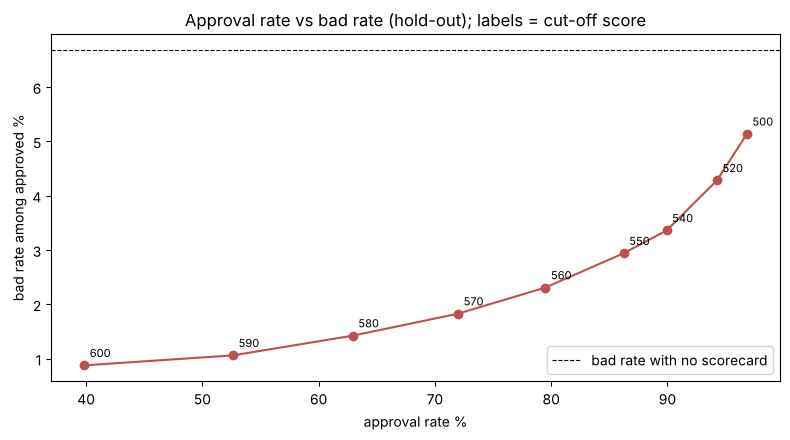

In [12]:
# hand check of one row: cut-off 560
ok = s_hold >= 560
manual = {"approval_rate": ok.mean(), "bad_rate_approved": y_hold[ok].mean(), "bads_rejected_share": y_hold[~ok].sum() / y_hold.sum()}
row = cut[cut.cutoff == 560].iloc[0]
print({k: round(v, 4) for k, v in manual.items()})
assert all(np.isclose(manual[k], row[k]) for k in manual)
print("OK: table row matches the manual calculation")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(cut["approval_rate"] * 100, cut["bad_rate_approved"] * 100, marker="o", color="#c0504d")
for r in cut.itertuples():
    ax.annotate(f"{int(r.cutoff)}", (r.approval_rate * 100, r.bad_rate_approved * 100), textcoords="offset points", xytext=(4, 6), fontsize=8)
ax.axhline(y_hold.mean() * 100, color="k", ls="--", lw=0.8, label="bad rate with no scorecard")
ax.set_xlabel("approval rate %"); ax.set_ylabel("bad rate among approved %"); ax.set_title("Approval rate vs bad rate (hold-out); labels = cut-off score"); ax.legend()
plt.tight_layout(); plt.savefig("../outputs/figures/cutoff_tradeoff.png", dpi=130); plt.show()

**Reading:** with no scorecard the bad rate is 6.7%. A cut-off of 560 approves about 80% of applicants and cuts the bad rate among approved to about 2.3% while rejecting about 72% of all bad customers (and 17% of good ones).
Raising the cut-off to 590 approves about half of applicants at a bad rate near 1%. **Choosing the cut-off is a business decision** (margin per good account vs loss per bad account, risk appetite, capacity); the table gives the trade-off, it does not choose.

## 6. Save results

In [13]:
disc.to_csv("../outputs/metrics/holdout_discrimination.csv")
ro_hold.to_csv("../outputs/metrics/holdout_rank_ordering.csv", index=False)
ro_dev.to_csv("../outputs/metrics/dev_rank_ordering.csv", index=False)
cal_hold.to_csv("../outputs/metrics/holdout_calibration_by_grade.csv", index=False)
cmp.to_csv("../outputs/metrics/holdout_calibration_options.csv")
cut.to_csv("../outputs/metrics/cutoff_table_holdout.csv", index=False)
csi_tbl.to_csv("../outputs/metrics/csi_dev_vs_holdout.csv", index=False)
ms_tbl = ro_dev[["grade", "min_score", "max_score", "rows", "bad_rate"]].rename(columns={"bad_rate": "pd_master_scale"})
ms_tbl.to_csv("../outputs/scorecard/grade_master_scale.csv", index=False)
with open("../outputs/scorecard/grade_edges.json", "w") as f:
    json.dump({"score_edges_from_development": edges.tolist()}, f, indent=2)
print("Saved validation tables, master scale and grade edges")

Saved validation tables, master scale and grade edges


## Summary (hold-out)

| Check | Result |
|---|---|
| AUC / Gini / KS | ~0.860 / ~0.719 / ~0.565 (development ~0.858 / 0.717 / 0.554), no overfitting |
| Rank ordering | strictly increasing bad rate over 10 grades on both sets (0.5% to 36%) |
| Calibration, overall | good: mean PD 6.6% vs 6.7% observed, slope 0.98 |
| Calibration, by grade | over-predicts the safest grades (obs/pred ~0.6-0.7); structural, also seen on development; HL rejects |
| Fix | grade master scale from development fixes grade-level calibration (HL p ~0.27); linear recalibration does not |
| Stability | score PSI ~0.0005 (random split, so expected) |

**Questions to answer in your own words (interview material)**
1. Why can a model have an excellent AUC and still be badly calibrated? Which of the two matters more for provisioning, and which for approve/decline?
2. The hold-out AUC is slightly *higher* than on development. Is that suspicious? What would be?
3. How do you explain to a risk committee that the PD in the safest grades is over-stated, and what do you propose?
4. Why is a low PSI between development and hold-out not evidence that the model is stable in production?

Next: write the reports (`model_development.md`, `model_validation.md`, `limitations.md`) and the README, then (optionally) the XGBoost challenger.